# MOVIES DB DATASET CREATION

In [6]:
from pathlib import Path
import pandas as pd

movies_dir = Path("Movies_DB_Datasets")
movies_dir.mkdir(exist_ok=True)

movies_queries_path = movies_dir / "movies_queries.xlsx"
raw_test_path = Path("../data/text2cypher-2024v1/test.xlsx")

if movies_queries_path.exists():
    # Use the existing Movies subset
    df_movies = pd.read_excel(movies_queries_path)
    print(
        f"Loaded {len(df_movies)} existing Movies queries "
        f"from {movies_queries_path}"
    )
else:
    # Create the Movies subset only if it does not already exist
    df = pd.read_excel(raw_test_path)
    df_movies = df[df["database_name"] == "movies"].copy()

    df_movies.to_excel(movies_queries_path, index=False)

    print(
        f"Created and saved {len(df_movies)} Movies queries "
        f"to {movies_queries_path}"
    )

Loaded 203 existing Movies queries from Movies_DB_Datasets\movies_queries.xlsx


Loaded existing Test Set: 100 queries.
Loaded existing Memory Set: 50 queries.


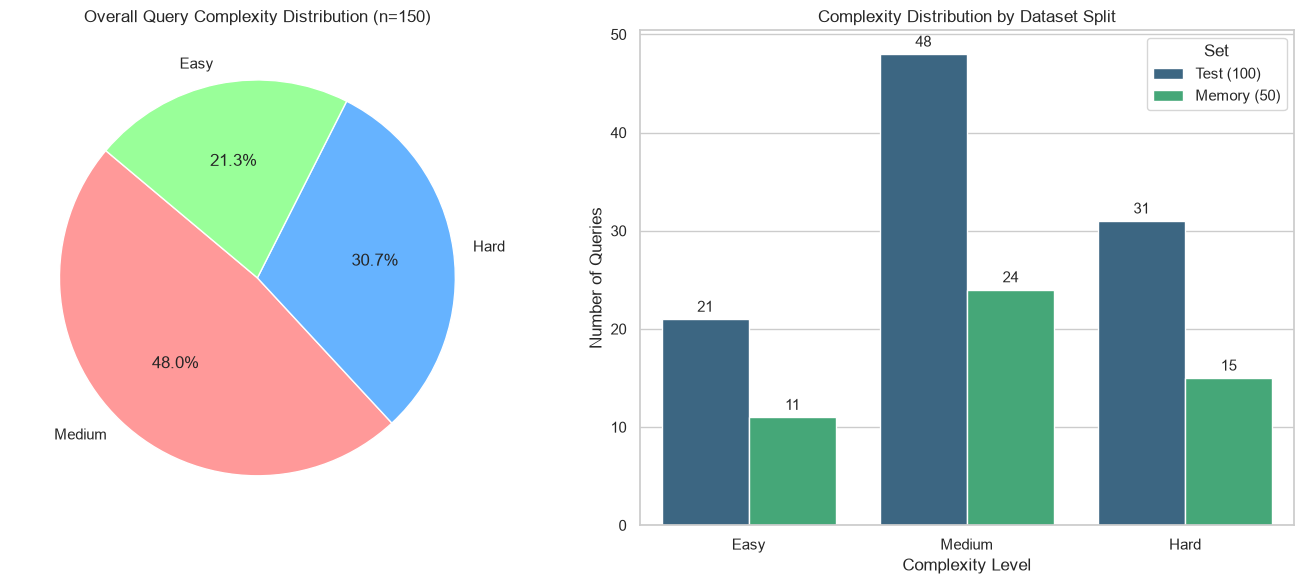

In [8]:
import pandas as pd
import re
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

# Define category based on Cypher complexity
def categorize_complexity(query):
    query_upper = str(query).upper()
    
    # Hard: Subqueries, aggregations, advanced pipelining
    hard_patterns = r'\b(COLLECT|FILTER|UNWIND|WITH|FOREACH|REDUCE|CALL|YIELD|APOC)\b'
    # Medium: Logic, sorting, basic math/counts
    medium_patterns = r'\b(ORDER BY|LIMIT|SKIP|COUNT|DISTINCT|EXISTS|IN|AND|OR|MIN|MAX|AVG|SUM)\b'
    
    if re.search(hard_patterns, query_upper):
        return 'Hard'
    elif re.search(medium_patterns, query_upper):
        return 'Medium'
    else:
        return 'Easy'

# Paths
movies_queries_path = Path("Movies_DB_Datasets/movies_queries.xlsx")
test_set_path = Path("Movies_DB_Datasets/100_test_queries_thesis.xlsx")
memory_set_path = Path("Movies_DB_Datasets/50_memory_queries_thesis.xlsx")


# Load the existing thesis datasets when available
if test_set_path.exists() and memory_set_path.exists():

    df_test = pd.read_excel(test_set_path).copy()
    df_memory = pd.read_excel(memory_set_path).copy()

    # Recreate the helper column for analysis and plotting
    df_test["complexity"] = df_test["cypher"].apply(categorize_complexity)
    df_memory["complexity"] = df_memory["cypher"].apply(categorize_complexity)

    print(f"Loaded existing Test Set: {len(df_test)} queries.")
    print(f"Loaded existing Memory Set: {len(df_memory)} queries.")


# Create the exact 100/50 split only if neither file exists
elif not test_set_path.exists() and not memory_set_path.exists():

    print("Thesis datasets not found. Creating them...")

    df = pd.read_excel(movies_queries_path)

    # Add complexity labels
    df["complexity"] = df["cypher"].apply(categorize_complexity)

    # Sample exactly 150 queries while preserving complexity distribution
    df_sampled, _ = train_test_split(
        df,
        train_size=150,
        stratify=df["complexity"],
        random_state=42
    )

    # Split into 100 evaluation and 50 memory queries
    df_test, df_memory = train_test_split(
        df_sampled,
        test_size=50,
        stratify=df_sampled["complexity"],
        random_state=42
    )

    df_test = df_test.copy()
    df_memory = df_memory.copy()

    # Save without the helper column
    df_test.drop(columns=["complexity"]).to_excel(
        test_set_path,
        index=False
    )

    df_memory.drop(columns=["complexity"]).to_excel(
        memory_set_path,
        index=False
    )

    print(f"Created Test Set: {len(df_test)} queries.")
    print(f"Created Memory Set: {len(df_memory)} queries.")


# Prevent accidental regeneration if only one file is missing
else:
    raise FileNotFoundError(
        "Only one of the two thesis dataset files exists. "
        "Check Movies_DB_Datasets before continuing."
    )

# Distribution Plots 
df_test['Set'] = 'Test (100)'
df_memory['Set'] = 'Memory (50)'
df_plot = pd.concat([df_test, df_memory])

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Plot A: Overall Distribution (Pie Chart)
complexity_counts = df_plot['complexity'].value_counts()
axes[0].pie(
    complexity_counts, 
    labels=complexity_counts.index, 
    autopct='%1.1f%%', 
    startangle=140,
    colors=['#ff9999','#66b3ff','#99ff99']
)
axes[0].set_title('Overall Query Complexity Distribution (n=150)')

# Plot B: Split Distribution (Bar Plot)
sns.countplot(
    data=df_plot, 
    x='complexity', 
    hue='Set', 
    order=['Easy', 'Medium', 'Hard'],
    palette='viridis',
    ax=axes[1]
)

# Add exact count labels above each bar
for container in axes[1].containers:
    axes[1].bar_label(
        container,
        fmt='%d',
        padding=3,
        fontsize=11
    )
    
axes[1].set_title('Complexity Distribution by Dataset Split')
axes[1].set_xlabel('Complexity Level')
axes[1].set_ylabel('Number of Queries')

plt.tight_layout()
# plt.savefig('Figures/Movies_Dataset/query_complexity_distribution.pdf', bbox_inches='tight')
plt.savefig('Figures/Movies_Dataset/query_complexity_distribution.png', dpi=300)
plt.show()

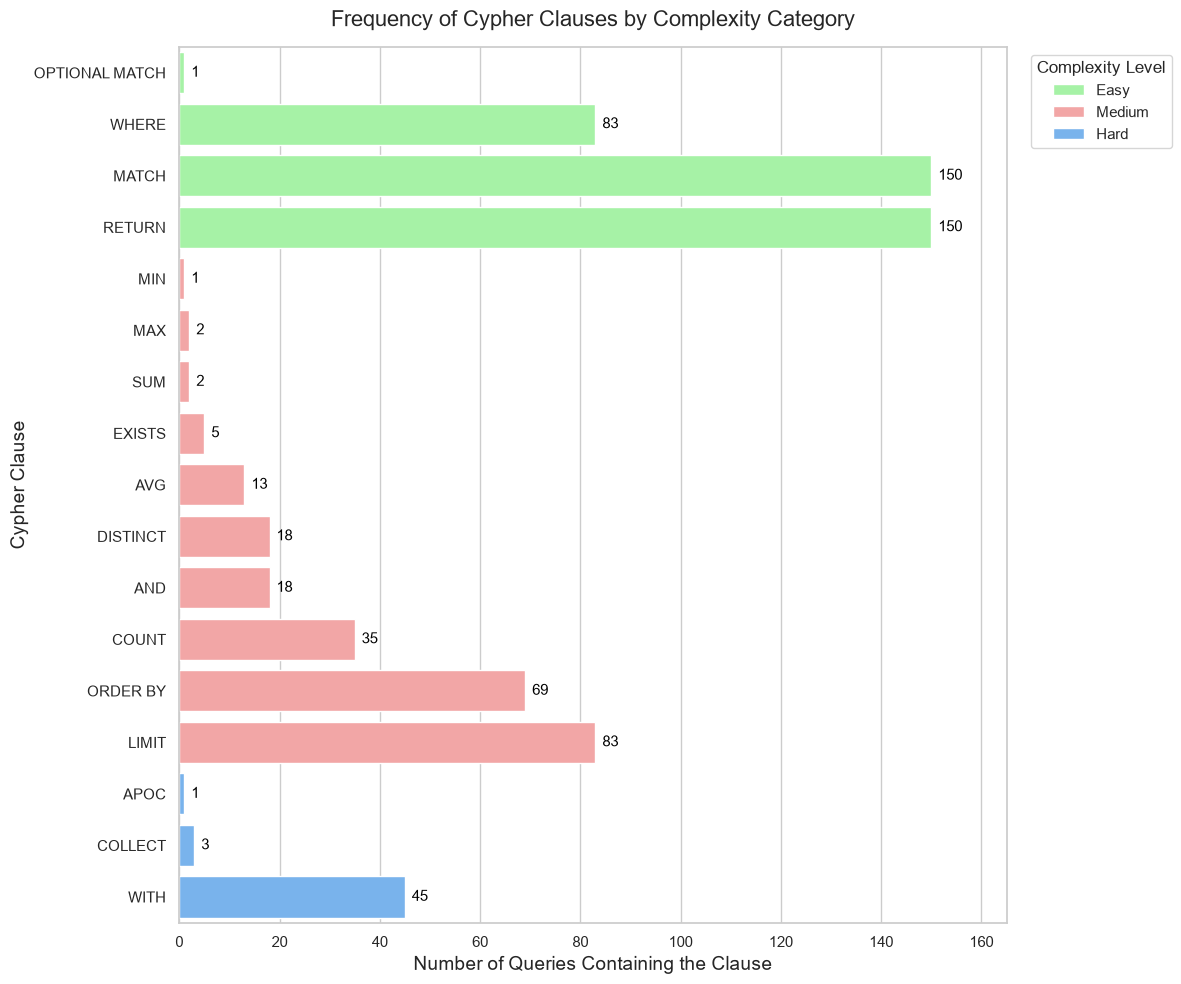

In [9]:
import pandas as pd
import re
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter

# Load the final 150-query experimental dataset
df_test = pd.read_excel('Movies_DB_Datasets/100_test_queries_thesis.xlsx')
df_memory = pd.read_excel('Movies_DB_Datasets/50_memory_queries_thesis.xlsx')

df = pd.concat(
    [df_test, df_memory],
    ignore_index=True
)

# Define the keyword rules
hard_keywords = [
    'COLLECT', 'FILTER', 'UNWIND', 'WITH',
    'FOREACH', 'REDUCE', 'CALL', 'YIELD', 'APOC'
]

medium_keywords = [
    'ORDER BY', 'LIMIT', 'SKIP', 'COUNT', 'DISTINCT',
    'EXISTS', 'IN', 'AND', 'OR', 'MIN', 'MAX', 'AVG', 'SUM'
]

easy_keywords = [
    'MATCH', 'OPTIONAL MATCH', 'WHERE', 'RETURN'
]

keyword_counts = {
    'Hard': Counter(),
    'Medium': Counter(),
    'Easy': Counter()
}

# Count occurrences in the 150 selected queries
for query in df['cypher'].dropna():
    q_upper = str(query).upper()

    for kw in hard_keywords:
        if re.search(rf'\b{kw}\b', q_upper):
            keyword_counts['Hard'][kw] += 1

    for kw in medium_keywords:
        if re.search(rf'\b{kw}\b', q_upper):
            keyword_counts['Medium'][kw] += 1

    for kw in easy_keywords:
        if re.search(rf'\b{kw}\b', q_upper):
            keyword_counts['Easy'][kw] += 1

# Prepare data for plotting
plot_data = []

for category, counts in keyword_counts.items():
    for kw, count in counts.items():
        if count > 0:
            plot_data.append({
                'Keyword': kw,
                'Count': count,
                'Complexity Trigger': category
            })

# Sort explicitly by Category first, then Count
category_order = {
    'Hard': 0,
    'Medium': 1,
    'Easy': 2
}

df_plot = pd.DataFrame(plot_data)

df_plot['Sort_Cat'] = df_plot['Complexity Trigger'].map(category_order)

df_plot = df_plot.sort_values(
    by=['Sort_Cat', 'Count'],
    ascending=[False, True]
)

# Generate the Plot
plt.figure(figsize=(12, 10))
sns.set_theme(style="whitegrid")

ax = sns.barplot(
    data=df_plot,
    x='Count',
    y='Keyword',
    hue='Complexity Trigger',
    dodge=False,
    palette={
        'Hard': '#66b3ff',
        'Medium': '#ff9999',
        'Easy': '#99ff99'
    }
)

# Add exact numbers to the end of each bar
for container in ax.containers:
    ax.bar_label(
        container,
        padding=5,
        fontsize=11,
        color='black'
    )

plt.title(
    'Frequency of Cypher Clauses by Complexity Category',
    fontsize=16,
    pad=15
)

plt.xlabel(
    'Number of Queries Containing the Clause',
    fontsize=14
)

plt.ylabel(
    'Cypher Clause',
    fontsize=14
)

# Move legend outside the plot area
plt.legend(
    title='Complexity Level',
    bbox_to_anchor=(1.02, 1),
    loc='upper left'
)

# Extend x-axis slightly to make room for labels
max_count = df_plot['Count'].max()
plt.xlim(0, max_count * 1.1)

plt.tight_layout()

# plt.savefig('Figures/Movies_Dataset/keyword_frequency_improved.pdf', bbox_inches='tight')
plt.savefig('Figures/Movies_Dataset/keyword_frequency_improved.png', dpi=300)

plt.show()

# END OF MOVIES DB DATASET CREATION

# MULTI DBS DATASET CREATION

In [10]:
import pandas as pd
from pathlib import Path

multi_db_dir = Path("Multi_DBs_Datasets")
multi_db_dir.mkdir(exist_ok=True)

five_databases_path = multi_db_dir / "five_databases_queries.xlsx"
raw_test_path = Path("../data/text2cypher-2024v1/test.xlsx")

databases = [
    "northwind",
    "companies",
    "twitch",
    "grandstack",
    "recommendations"
]


if five_databases_path.exists():

    # Use the existing cleaned multi-database dataset
    df_selected = pd.read_excel(five_databases_path)

    print(
        f"Loaded {len(df_selected)} existing queries "
        f"from {five_databases_path}"
    )

else:

    # Create the cleaned multi-database dataset only if it does not exist
    print("five_databases_queries.xlsx not found. Creating it...")

    df = pd.read_excel(raw_test_path)

    # Select the five databases
    df_selected = df[df["database_name"].isin(databases)].copy()

    # Keep only valid rows
    required_columns = [
        "question",
        "schema",
        "cypher",
        "database_name",
        "username",
        "password"
    ]

    df_selected = df_selected.dropna(subset=required_columns)

    for col in required_columns:
        df_selected = df_selected[
            df_selected[col].astype(str).str.strip() != ""
        ]

    # Use the Neo4j demo endpoint
    df_selected["url"] = "bolt+ssc://demo.neo4jlabs.com"

    # Check duplicates
    exact_duplicates = df_selected.duplicated().sum()

    question_duplicates = df_selected.duplicated(
        subset=["database_name", "question"]
    ).sum()

    print(f"Exact duplicate rows: {exact_duplicates}")
    print(f"Duplicate questions: {question_duplicates}")

    # Remove duplicate questions within each database
    df_selected = df_selected.drop_duplicates(
        subset=["database_name", "question"],
        keep="first"
    )

    # Verify that every database contains enough queries
    counts = df_selected["database_name"].value_counts()

    print("\nValid queries per database:")
    print(counts)

    for database in databases:
        if counts.get(database, 0) < 150:
            raise ValueError(
                f"{database} has only "
                f"{counts.get(database, 0)} valid unique queries."
            )

    df_selected.to_excel(
        five_databases_path,
        index=False
    )

    print(
        f"\nCreated and saved {len(df_selected)} valid unique queries "
        f"to {five_databases_path}"
    )

Loaded 1036 existing queries from Multi_DBs_Datasets\five_databases_queries.xlsx


Loaded existing Test Set: 500 queries.
Loaded existing Memory Set: 250 queries.

Test queries per database:
database_name
northwind          100
companies          100
twitch             100
grandstack         100
recommendations    100
Name: count, dtype: int64

Memory queries per database:
database_name
northwind          50
companies          50
twitch             50
grandstack         50
recommendations    50
Name: count, dtype: int64

Test complexity:
complexity
Medium    230
Hard      190
Easy       80
Name: count, dtype: int64

Memory complexity:
complexity
Medium    112
Hard       97
Easy       41
Name: count, dtype: int64

Duplicates inside Test: 0
Duplicates inside Memory: 0
Test/Memory question overlap: 0


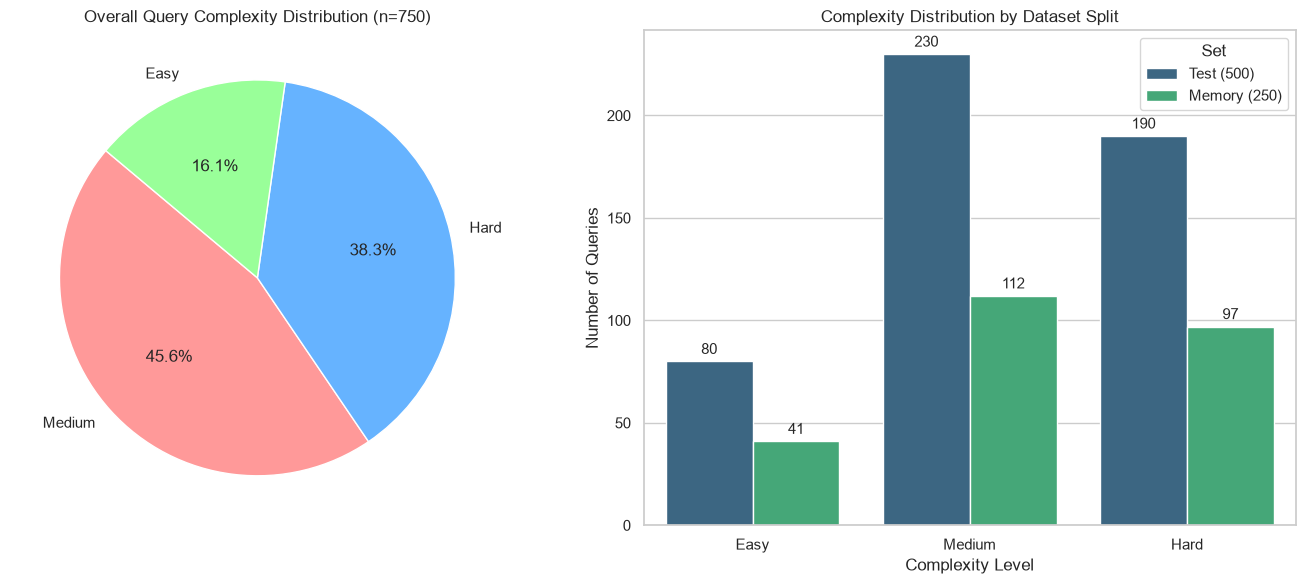

In [12]:
import pandas as pd
import re
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

# Define complexity categories
def categorize_complexity(query):
    query_upper = str(query).upper()
    hard_patterns = r'\b(COLLECT|FILTER|UNWIND|WITH|FOREACH|REDUCE|CALL|YIELD|APOC)\b'
    medium_patterns = r'\b(ORDER BY|LIMIT|SKIP|COUNT|DISTINCT|EXISTS|IN|AND|OR|MIN|MAX|AVG|SUM)\b'

    if re.search(hard_patterns, query_upper):
        return 'Hard'
    elif re.search(medium_patterns, query_upper):
        return 'Medium'
    else:
        return 'Easy'

# Dataset paths
five_databases_path = Path("Multi_DBs_Datasets/five_databases_queries.xlsx")
test_set_path = Path("Multi_DBs_Datasets/500_test_queries_thesis.xlsx")
memory_set_path = Path("Multi_DBs_Datasets/250_memory_queries_thesis.xlsx")

# Load the existing multi-database experiment datasets
if test_set_path.exists() and memory_set_path.exists():

    df_test = pd.read_excel(test_set_path).copy()
    df_memory = pd.read_excel(memory_set_path).copy()

    # Recreate the helper column used by the analysis below
    df_test["complexity"] = df_test["cypher"].apply(
        categorize_complexity
    )

    df_memory["complexity"] = df_memory["cypher"].apply(
        categorize_complexity
    )

    print(
        f"Loaded existing Test Set: "
        f"{len(df_test)} queries."
    )

    print(
        f"Loaded existing Memory Set: "
        f"{len(df_memory)} queries."
    )

# Recreate the datasets only if both files are missing
elif not test_set_path.exists() and not memory_set_path.exists():

    print(
        "Multi-database experiment datasets not found. "
        "Creating them..."
    )

    df = pd.read_excel(five_databases_path)

    df["complexity"] = df["cypher"].apply(
        categorize_complexity
    )

    test_sets = []
    memory_sets = []

    # Sample 150 queries from each database
    for database in df["database_name"].unique():

        df_db = df[
            df["database_name"] == database
        ].copy()

        df_sampled, _ = train_test_split(
            df_db,
            train_size=150,
            stratify=df_db["complexity"],
            random_state=42
        )

        # 100 evaluation + 50 memory queries per database
        df_test_db, df_memory_db = train_test_split(
            df_sampled,
            test_size=50,
            stratify=df_sampled["complexity"],
            random_state=42
        )

        test_sets.append(df_test_db)
        memory_sets.append(df_memory_db)

        print(
            f"{database}: "
            f"{len(df_test_db)} Test, "
            f"{len(df_memory_db)} Memory"
        )

        print(
            df_test_db["complexity"]
            .value_counts()
            .to_dict()
        )

    # Combine all five databases
    df_test = pd.concat(
        test_sets,
        ignore_index=True
    )

    df_memory = pd.concat(
        memory_sets,
        ignore_index=True
    )

    # Save the final datasets without the helper column
    df_test.drop(
        columns=["complexity"]
    ).to_excel(
        test_set_path,
        index=False
    )

    df_memory.drop(
        columns=["complexity"]
    ).to_excel(
        memory_set_path,
        index=False
    )

    print(
        f"\nCreated Test Set: "
        f"{len(df_test)} queries."
    )

    print(
        f"Created Memory Set: "
        f"{len(df_memory)} queries."
    )

# Avoid accidentally regenerating only half of the experiment
else:
    raise FileNotFoundError(
        "Only one of the two multi-database experiment "
        "datasets exists. Check Multi_DBs_Datasets "
        "before continuing."
    )

# Check final distributions
print("\nTest queries per database:")
print(df_test["database_name"].value_counts())

print("\nMemory queries per database:")
print(df_memory["database_name"].value_counts())

print("\nTest complexity:")
print(df_test["complexity"].value_counts())

print("\nMemory complexity:")
print(df_memory["complexity"].value_counts())

# Check for Test/Memory leakage
print("\nDuplicates inside Test:",
      df_test.duplicated(subset=['database_name', 'question']).sum())

print("Duplicates inside Memory:",
      df_memory.duplicated(subset=['database_name', 'question']).sum())

overlap = df_test.merge(
    df_memory,
    on=['database_name', 'question'],
    how='inner'
)

print(f"Test/Memory question overlap: {len(overlap)}")

if len(overlap) > 0:
    raise ValueError("Test and Memory sets contain overlapping questions.")

# Plot complexity distribution
df_test['Set'] = 'Test (500)'
df_memory['Set'] = 'Memory (250)'
df_plot = pd.concat([df_test, df_memory])

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

complexity_counts = df_plot['complexity'].value_counts()
axes[0].pie(
    complexity_counts,
    labels=complexity_counts.index,
    autopct='%1.1f%%',
    startangle=140,
    colors=['#ff9999', '#66b3ff', '#99ff99']
)
axes[0].set_title('Overall Query Complexity Distribution (n=750)')

sns.countplot(
    data=df_plot,
    x='complexity',
    hue='Set',
    order=['Easy', 'Medium', 'Hard'],
    palette='viridis',
    ax=axes[1]
)

# Add exact count labels above each bar
for container in axes[1].containers:
    axes[1].bar_label(
        container,
        fmt='%d',
        padding=3,
        fontsize=11
    )
    
axes[1].set_title('Complexity Distribution by Dataset Split')
axes[1].set_xlabel('Complexity Level')
axes[1].set_ylabel('Number of Queries')

plt.tight_layout()

# plt.savefig('Figures/MultiDB_Dataset/query_complexity_distribution.pdf', bbox_inches='tight')
plt.savefig('Figures/MultiDB_Dataset/query_complexity_distribution.png', dpi=300)
plt.show()

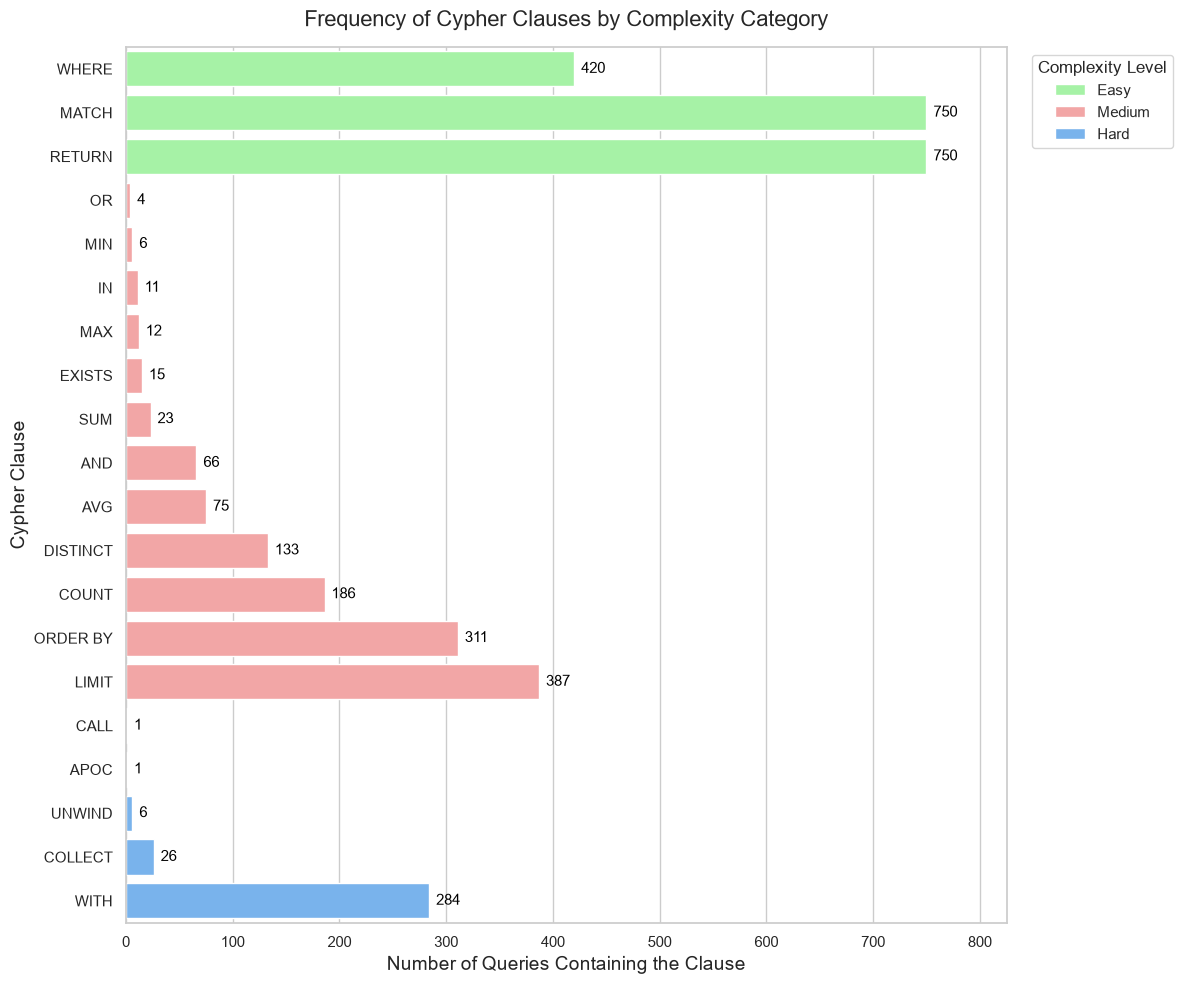

In [13]:
import pandas as pd
import re
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter

# Load final datasets
df_test = pd.read_excel("Multi_DBs_Datasets/500_test_queries_thesis.xlsx")
df_memory = pd.read_excel("Multi_DBs_Datasets/250_memory_queries_thesis.xlsx")
df = pd.concat([df_test, df_memory], ignore_index=True)

# Define keyword categories
hard_keywords = ['COLLECT', 'FILTER', 'UNWIND', 'WITH', 'FOREACH', 'REDUCE', 'CALL', 'YIELD', 'APOC']
medium_keywords = ['ORDER BY', 'LIMIT', 'SKIP', 'COUNT', 'DISTINCT', 'EXISTS', 'IN', 'AND', 'OR', 'MIN', 'MAX', 'AVG', 'SUM']
easy_keywords = ['MATCH', 'OPTIONAL MATCH', 'WHERE', 'RETURN']

keyword_counts = {'Hard': Counter(), 'Medium': Counter(), 'Easy': Counter()}

# Count keyword occurrences
for query in df['cypher'].dropna():
    q_upper = str(query).upper()

    for kw in hard_keywords:
        if re.search(rf'\b{kw}\b', q_upper):
            keyword_counts['Hard'][kw] += 1

    for kw in medium_keywords:
        if re.search(rf'\b{kw}\b', q_upper):
            keyword_counts['Medium'][kw] += 1

    for kw in easy_keywords:
        if re.search(rf'\b{kw}\b', q_upper):
            keyword_counts['Easy'][kw] += 1

# Prepare plot data
plot_data = []

for category, counts in keyword_counts.items():
    for kw, count in counts.items():
        if count > 0:
            plot_data.append({
                'Keyword': kw,
                'Count': count,
                'Complexity Trigger': category
            })

category_order = {'Hard': 0, 'Medium': 1, 'Easy': 2}
df_plot = pd.DataFrame(plot_data)
df_plot['Sort_Cat'] = df_plot['Complexity Trigger'].map(category_order)
df_plot = df_plot.sort_values(
    by=['Sort_Cat', 'Count'],
    ascending=[False, True]
)

# Plotting
plt.figure(figsize=(12, 10))
sns.set_theme(style="whitegrid")

ax = sns.barplot(
    data=df_plot,
    x='Count',
    y='Keyword',
    hue='Complexity Trigger',
    dodge=False,
    palette={'Hard': '#66b3ff', 'Medium': '#ff9999', 'Easy': '#99ff99'}
)

for container in ax.containers:
    ax.bar_label(container, padding=5, fontsize=11, color='black')

plt.title('Frequency of Cypher Clauses by Complexity Category', fontsize=16, pad=15)
plt.xlabel('Number of Queries Containing the Clause', fontsize=14)
plt.ylabel('Cypher Clause', fontsize=14)
plt.legend(title='Complexity Level', bbox_to_anchor=(1.02, 1), loc='upper left')

max_count = df_plot['Count'].max()
plt.xlim(0, max_count * 1.1)

plt.tight_layout()

# plt.savefig('Figures/MultiDB_Dataset/keyword_frequency_improved.pdf', bbox_inches='tight')
plt.savefig('Figures/MultiDB_Dataset/keyword_frequency_improved.png', dpi=300)
plt.show()